# 05 — Dataset Exploration
Validate schema quality and inspect learnability before model training.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
df = pd.read_csv(PROJECT_ROOT / "data" / "synthetic" / "synthetic_snapshots.csv")
print("rows", len(df), "snapshots", df.snapshot_id.nunique(), "scenarios", df.scenario_id.nunique())


rows 626000 snapshots 2000 scenarios 60


In [2]:
missing = df.isna().mean().sort_values(ascending=False)
print("Top missing ratios:\n", missing.head(10))

print("Scenario distribution:\n", df.groupby("scenario_id").snapshot_id.nunique().describe())


Top missing ratios:
 snapshot_id          0.0
scenario_id          0.0
simulation_run_id    0.0
timestamp_sec        0.0
road_segment_id      0.0
current_speed_kmh    0.0
current_density      0.0
queue_length         0.0
capacity_factor      0.0
closure_flag         0.0
dtype: float64
Scenario distribution:
 count    60.000000
mean     33.333333
std       0.475383
min      33.000000
25%      33.000000
50%      33.000000
75%      34.000000
max      34.000000
Name: snapshot_id, dtype: float64


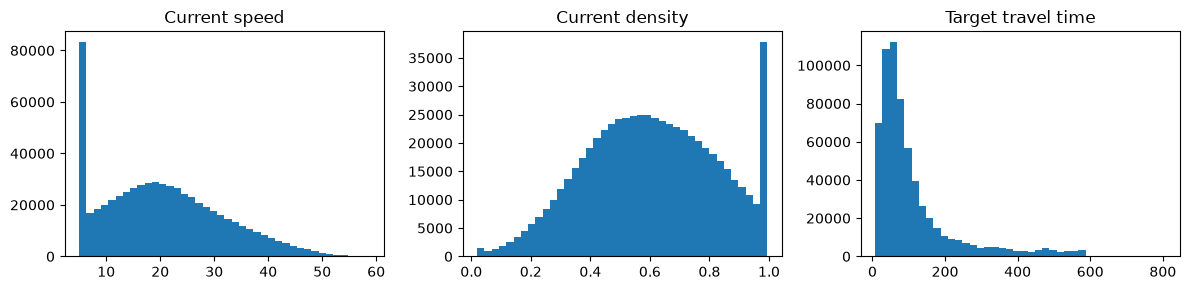

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12,3))
axes[0].hist(df.current_speed_kmh, bins=40)
axes[0].set_title("Current speed")
axes[1].hist(df.current_density, bins=40)
axes[1].set_title("Current density")
axes[2].hist(df.target_travel_time_sec, bins=40)
axes[2].set_title("Target travel time")
plt.tight_layout()
plt.show()


                        current_speed_kmh  current_density  queue_length  \
current_speed_kmh                1.000000        -0.867256     -0.758741   
current_density                 -0.867256         1.000000      0.860223   
queue_length                    -0.758741         0.860223      1.000000   
capacity_factor                  0.206807        -0.224783     -0.273439   
target_travel_time_sec          -0.649271         0.660146      0.741258   

                        capacity_factor  target_travel_time_sec  
current_speed_kmh              0.206807               -0.649271  
current_density               -0.224783                0.660146  
queue_length                  -0.273439                0.741258  
capacity_factor                1.000000               -0.302385  
target_travel_time_sec        -0.302385                1.000000  


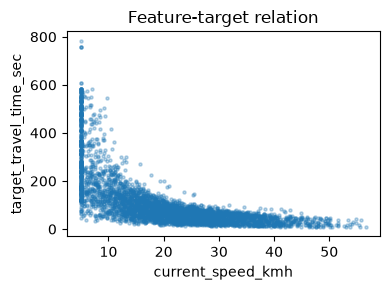

In [4]:
corr = df[["current_speed_kmh", "current_density", "queue_length", "capacity_factor", "target_travel_time_sec"]].corr()
print(corr)

sample = df.sample(4000, random_state=42)
plt.figure(figsize=(4,3))
plt.scatter(sample.current_speed_kmh, sample.target_travel_time_sec, s=5, alpha=0.3)
plt.xlabel("current_speed_kmh")
plt.ylabel("target_travel_time_sec")
plt.title("Feature-target relation")
plt.tight_layout()
plt.show()


## Leakage checks
- Confirm `target_travel_time_sec` is not embedded into input features.
- Split by `scenario_id` in Notebook 08.
- Stop and fix schema if any alignment issues are detected.


In [5]:
assert (df.prediction_horizon_sec == 300).all(), "Unexpected prediction horizon"
assert df.target_travel_time_sec.min() > 0, "Non-positive targets found"
print("Basic schema checks passed")


Basic schema checks passed
